In [1]:
import numpy as np
import cv2, os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Add, Concatenate, Conv2D,
    Input, Lambda, LeakyReLU,
    UpSampling2D, ZeroPadding2D
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.losses import (
    binary_crossentropy,
    sparse_categorical_crossentropy
)

In [2]:
YOLOV3_LAYER_LIST = [
    'yolo_darknet',
    'yolo_conv_0',
    'yolo_output_0',
    'yolo_conv_1',
    'yolo_output_1',
    'yolo_conv_2',
    'yolo_output_2'
]

yolo_anchors = np.array([
    (10, 13), (16, 30), (33, 23),
    (30, 61), (62, 45), (59, 119),
    (116, 90), (156, 198), (373, 326)
], np.float32) / 416

yolo_anchor_masks = np.array([[6, 7, 8], [3, 4, 5], [0, 1, 2]])

class_names = [
    'person', 'bicycle', 'car', 'motorbike', 'aeroplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench',
    'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra',
    'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee',
    'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
    'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup',
    'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange',
    'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'sofa',
    'pottedplant', 'bed', 'diningtable', 'toilet', 'tvmonitor', 'laptop', 'mouse',
    'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear',
    'hair drier', 'toothbrush'
]


In [3]:
def load_darknet_weights(model, weights_file):
    wf = open(weights_file, 'rb')
    major, minor, revision, seen, _ = np.fromfile(wf, dtype=np.int32, count=5)

    layers = YOLOV3_LAYER_LIST

    for layer_name in layers:
        sub_model = model.get_layer(layer_name)
        for i, layer in enumerate(sub_model.layers):
            if not layer.name.startswith('conv2d'):
                continue
            batch_norm = None
            if i + 1 < len(sub_model.layers) and sub_model.layers[i + 1].name.startswith('batch_norm'):
                batch_norm = sub_model.layers[i + 1]
            filters = layer.filters
            size = layer.kernel_size[0]
            in_dim = layer.input.shape[-1]
            if batch_norm is None:
                conv_bias = np.fromfile(wf, dtype=np.float32, count=filters)
            else:
                bn_weights = np.fromfile(wf, dtype=np.float32, count=4 * filters)
                bn_weights = bn_weights.reshape((4, filters))[[1, 0, 2, 3]]

            conv_shape = (filters, in_dim, size, size)
            conv_weights = np.fromfile(wf, dtype=np.float32, count=np.prod(conv_shape))
            conv_weights = conv_weights.reshape(conv_shape).transpose([2, 3, 1, 0])

            if batch_norm is None:
                layer.set_weights([conv_weights, conv_bias])
            else:
                layer.set_weights([conv_weights])
                batch_norm.set_weights(bn_weights)

    assert len(wf.read()) == 0, 'failed to read all data'
    wf.close()

# -------------------------
# Utility functions
# -------------------------
def transform_images(x, size):
    x = tf.image.resize(x, (size, size))
    x = x / 255.0
    return x

def broadcast_iou(box_1, box_2):
    box_1 = tf.expand_dims(box_1, -2)
    box_2 = tf.expand_dims(box_2, 0)
    new_shape = tf.broadcast_dynamic_shape(tf.shape(box_1), tf.shape(box_2))
    box_1 = tf.broadcast_to(box_1, new_shape)
    box_2 = tf.broadcast_to(box_2, new_shape)
    int_w = tf.maximum(tf.minimum(box_1[..., 2], box_2[..., 2]) - tf.maximum(box_1[..., 0], box_2[..., 0]), 0)
    int_h = tf.maximum(tf.minimum(box_1[..., 3], box_2[..., 3]) - tf.maximum(box_1[..., 1], box_2[..., 1]), 0)
    int_area = int_w * int_h
    box_1_area = (box_1[..., 2] - box_1[..., 0]) * (box_1[..., 3] - box_1[..., 1])
    box_2_area = (box_2[..., 2] - box_2[..., 0]) * (box_2[..., 3] - box_2[..., 1])
    return int_area / (box_1_area + box_2_area - int_area)


In [4]:
class BatchNormalization(tf.keras.layers.BatchNormalization):
    def call(self, x, training=False):
        if training is None:
            training = False
        if isinstance(training, bool):
            final_training_state = training and self.trainable
        else:
            final_training_state = tf.logical_and(training, self.trainable)
        return super(BatchNormalization, self).call(x, training=final_training_state)

def DarknetConv(x, filters, size, strides=1, batch_norm=True):
    if strides == 1:
        padding = 'same'
    else:
        x = ZeroPadding2D(((1, 0), (1, 0)))(x)
        padding = 'valid'
    x = Conv2D(filters=filters, kernel_size=size,
               strides=strides, padding=padding,
               use_bias=not batch_norm, kernel_regularizer=l2(0.0005))(x)
    if batch_norm:
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.1)(x)
    return x

def DarknetResidual(x, filters):
    prev = x
    x = DarknetConv(x, filters // 2, 1)
    x = DarknetConv(x, filters, 3)
    x = Add()([prev, x])
    return x

def DarknetBlock(x, filters, blocks):
    x = DarknetConv(x, filters, 3, strides=2)
    for _ in range(blocks):
        x = DarknetResidual(x, filters)
    return x

def Darknet(name=None):
    x = inputs = Input([None, None, 3])
    x = DarknetConv(x, 32, 3)
    x = DarknetBlock(x, 64, 1)
    x = DarknetBlock(x, 128, 2)
    x = x_36 = DarknetBlock(x, 256, 8)
    x = x_61 = DarknetBlock(x, 512, 8)
    x = DarknetBlock(x, 1024, 4)
    return tf.keras.Model(inputs, (x_36, x_61, x), name=name)

def YoloConv(x_in, filters, name=None):
    if isinstance(x_in, tuple):
        inputs = Input(x_in[0].shape[1:]), Input(x_in[1].shape[1:])
        x, x_skip = inputs
        x = DarknetConv(x, filters, 1)
        x = UpSampling2D(2)(x)
        x = Concatenate()([x, x_skip])
    else:
        x = inputs = Input(x_in.shape[1:])
    x = DarknetConv(x, filters, 1)
    x = DarknetConv(x, filters * 2, 3)
    x = DarknetConv(x, filters, 1)
    x = DarknetConv(x, filters * 2, 3)
    x = DarknetConv(x, filters, 1)
    return Model(inputs, x, name=name)(x_in)

def YoloOutput(x_in, filters, anchors, classes, name=None):
    x = inputs = Input(x_in.shape[1:])
    x = DarknetConv(x, filters * 2, 3)
    x = DarknetConv(x, anchors * (classes + 5), 1, batch_norm=False)
    x = Lambda(lambda x: tf.reshape(x, (-1, tf.shape(x)[1], tf.shape(x)[2], anchors, classes + 5)))(x)
    return tf.keras.Model(inputs, x, name=name)(x_in)

In [6]:
def yolo_boxes(pred, anchors, classes):
    '''pred: (batch_size, grid, grid, anchors, (x, y, w, h, obj, ...classes))'''
    grid_size = tf.shape(pred)[1]
    box_xy, box_wh, objectness, class_probs = tf.split(
        pred, (2, 2, 1, classes), axis=-1)
    box_xy = tf.sigmoid(box_xy)
    objectness = tf.sigmoid(objectness)
    class_probs = tf.sigmoid(class_probs)
    pred_box = tf.concat((box_xy, box_wh), axis=-1)  # original xywh for loss

    # build grid
    grid = tf.meshgrid(tf.range(grid_size), tf.range(grid_size))
    grid = tf.expand_dims(tf.stack(grid, axis=-1), axis=2)  # [gx, gy, 1, 2]

    # xy normalized relative to the whole image
    box_xy = (box_xy + tf.cast(grid, tf.float32)) / tf.cast(grid_size, tf.float32)
    box_wh = tf.exp(box_wh) * anchors  # anchors already normalized (divided by 416)

    # box corners in x,y order
    box_x1y1 = box_xy - box_wh / 2
    box_x2y2 = box_xy + box_wh / 2

    # REORDER to [y1, x1, y2, x2] because tf.image.* expects that.
    y1 = box_x1y1[..., 1:2]
    x1 = box_x1y1[..., 0:1]
    y2 = box_x2y2[..., 1:2]
    x2 = box_x2y2[..., 0:1]
    bbox = tf.concat([y1, x1, y2, x2], axis=-1)

    return bbox, objectness, class_probs, pred_box

def yolo_nms(outputs, anchors, masks, classes):
    b, c, t = [], [], []
    for o in outputs:
        b.append(tf.reshape(o[0], (tf.shape(o[0])[0], -1, tf.shape(o[0])[-1])))
        c.append(tf.reshape(o[1], (tf.shape(o[1])[0], -1, tf.shape(o[1])[-1])))
        t.append(tf.reshape(o[2], (tf.shape(o[2])[0], -1, tf.shape(o[2])[-1])))
    bbox = tf.concat(b, axis=1)
    confidence = tf.concat(c, axis=1)
    class_probs = tf.concat(t, axis=1)
    scores = confidence * class_probs
    boxes, scores, classes, valid_detections = tf.image.combined_non_max_suppression(
        boxes=tf.reshape(bbox, (tf.shape(bbox)[0], -1, 1, 4)),
        scores=tf.reshape(
            scores,
            (tf.shape(scores)[0], -1, tf.shape(scores)[-1])
        ),
        max_output_size_per_class=100,
        max_total_size=100,
        iou_threshold=0.5,
        score_threshold=0.5
    )
    return boxes, scores, classes, valid_detections

def YoloV3(size=None, channels=3, anchors=yolo_anchors, masks=yolo_anchor_masks, classes=80, training=False):
    x = inputs = Input([size, size, channels])
    x_36, x_61, x = Darknet(name='yolo_darknet')(x)
    x = YoloConv(x, 512, name='yolo_conv_0')
    output_0 = YoloOutput(x, 512, len(masks[0]), classes, name='yolo_output_0')
    x = YoloConv((x, x_61), 256, name='yolo_conv_1')
    output_1 = YoloOutput(x, 256, len(masks[1]), classes, name='yolo_output_1')
    x = YoloConv((x, x_36), 128, name='yolo_conv_2')
    output_2 = YoloOutput(x, 128, len(masks[2]), classes, name='yolo_output_2')
    if training:
        return Model(inputs, (output_0, output_1, output_2), name='yolov3')
    boxes_0 = Lambda(lambda x: yolo_boxes(x, anchors[masks[0]], classes), name='yolo_boxes_0')(output_0)
    boxes_1 = Lambda(lambda x: yolo_boxes(x, anchors[masks[1]], classes), name='yolo_boxes_1')(output_1)
    boxes_2 = Lambda(lambda x: yolo_boxes(x, anchors[masks[2]], classes), name='yolo_boxes_2')(output_2)
    outputs = Lambda(lambda x: yolo_nms(x, anchors, masks, classes), name='yolo_nms')((boxes_0[:3], boxes_1[:3], boxes_2[:3]))
    return Model(inputs, outputs, name='yolov3')



In [7]:
# Instantiate model
yolo = YoloV3(size=416, classes=80)
yolo.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "yolov3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 416, 416,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_darknet        │ [(None, 52, 52,   │ 40,620,640 │ input_layer[0][0] │
│ (Functional)        │ 256), (None, 26,  │            │                   │
│                     │ 26, 512), (None,  │            │                   │
│                     │ 13, 13, 1024)]    │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_conv_0         │ (None, 13, 13,    │ 11,024,384 │ yolo_darknet[0][… │
│ (Functional)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_conv_1         │ (None, 26, 26,    │  2,957,312 │ yolo_conv_0[0][0… │
│ (Functional)        │ 256)              │            │ yolo_darknet[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_conv_2         │ (None, 52, 52,    │    741,376 │ yolo_conv_1[0][0… │
│ (Functional)        │ 128)              │            │ yolo_darknet[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_output_0       │ (None, 13, 13, 3, │  4,984,063 │ yolo_conv_0[0][0] │
│ (Functional)        │ 85)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_output_1       │ (None, 26, 26, 3, │  1,312,511 │ yolo_conv_1[0][0] │
│ (Functional)        │ 85)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_output_2       │ (None, 52, 52, 3, │    361,471 │ yolo_conv_2[0][0] │
│ (Functional)        │ 85)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_boxes_0        │ [(None, 13, 13,   │          0 │ yolo_output_0[0]… │
│ (Lambda)            │ 3, 4), (None, 13, │            │                   │
│                     │ 13, 3, 1), (None, │            │                   │
│                     │ 13, 13, 3, 80),   │            │                   │
│                     │ (None, 13, 13, 3, │            │                   │
│                     │ 4)]               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_boxes_1        │ [(None, 26, 26,   │          0 │ yolo_output_1[0]… │
│ (Lambda)            │ 3, 4), (None, 26, │            │                   │
│                     │ 26, 3, 1), (None, │            │                   │
│                     │ 26, 26, 3, 80),   │            │                   │
│                     │ (None, 26, 26, 3, │            │                   │
│                     │ 4)]               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_boxes_2        │ [(None, 52, 52,   │          0 │ yolo_output_2[0]… │
│ (Lambda)            │ 3, 4), (None, 52, │            │                   │
│                     │ 52, 3, 1), (None, │            │                   │
│                     │ 52, 52, 3, 80),   │            │                   │
│                     │ (None, 52, 52, 3, │            │                   │
│                     │ 4)]               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yolo_nms (Lambda)   │ [(None, 100, 4),  │          0 │ yolo_boxes_0[0][… │
│                     │ (None, 100),      │            │ yolo_boxes_0[0][

 Total params: 62,001,757 (236.52 MB)

 Trainable params: 61,949,149 (236.32 MB)

 Non-trainable params: 52,608 (205.50 KB)

In [8]:
def predict_and_draw(image_file, model, class_names, input_size=416, visualize=True, figsize=(12, 12)):
    # Read + preprocess
    img_raw = tf.image.decode_image(open(image_file, 'rb').read(), channels=3)
    img = tf.expand_dims(img_raw, 0)
    img = transform_images(img, input_size)

    # Predict
    boxes, scores, classes, nums = model.predict(img)

    # boxes returned by combined_nms are normalized in [y1, x1, y2, x2]
    img_bgr = cv2.imread(image_file)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    ih, iw = img_rgb.shape[:2]

    num = int(nums[0])
    for i in range(num):
        y1, x1, y2, x2 = boxes[0][i]  # normalized coordinates [y1, x1, y2, x2]
        # scale to image size
        x1 = int(x1 * iw)
        x2 = int(x2 * iw)
        y1 = int(y1 * ih)
        y2 = int(y2 * ih)

        # clamp (just in case)
        x1 = max(0, min(x1, iw - 1))
        x2 = max(0, min(x2, iw - 1))
        y1 = max(0, min(y1, ih - 1))
        y2 = max(0, min(y2, ih - 1))

        # draw rectangle and label
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cls = int(classes[0][i])
        score = scores[0][i]
        label = f"{class_names[cls]}: {score:.2f}"
        cv2.putText(img_rgb, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

    if visualize:
        plt.figure(figsize=figsize)
        plt.imshow(img_rgb)
        plt.axis('off')
        plt.show()

    return boxes, scores, classes, nums


In [9]:

!wget https://pjreddie.com/media/files/yolov3.weights -O /content/yolov3.weights
load_darknet_weights(yolo, '/content/yolov3.weights')


--2025-12-04 06:07:04--  https://pjreddie.com/media/files/yolov3.weights
Resolving pjreddie.com (pjreddie.com)... 104.21.88.156, 172.67.185.199, 2606:4700:3037::6815:589c, ...
Connecting to pjreddie.com (pjreddie.com)|104.21.88.156|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://data.pjreddie.com/files/yolov3.weights [following]
--2025-12-04 06:07:04--  https://data.pjreddie.com/files/yolov3.weights
Resolving data.pjreddie.com (data.pjreddie.com)... 104.21.88.156, 172.67.185.199, 2606:4700:3037::6815:589c, ...
Connecting to data.pjreddie.com (data.pjreddie.com)|104.21.88.156|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 248007048 (237M) [application/octet-stream]
Saving to: ‘/content/yolov3.weights’

/content/yolov3.wei 100%[===================>] 236.52M  68.2MB/s    in 3.4s    

2025-12-04 06:07:08 (69.1 MB/s) - ‘/content/yolov3.weights’ saved [248007048/248007048]



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step


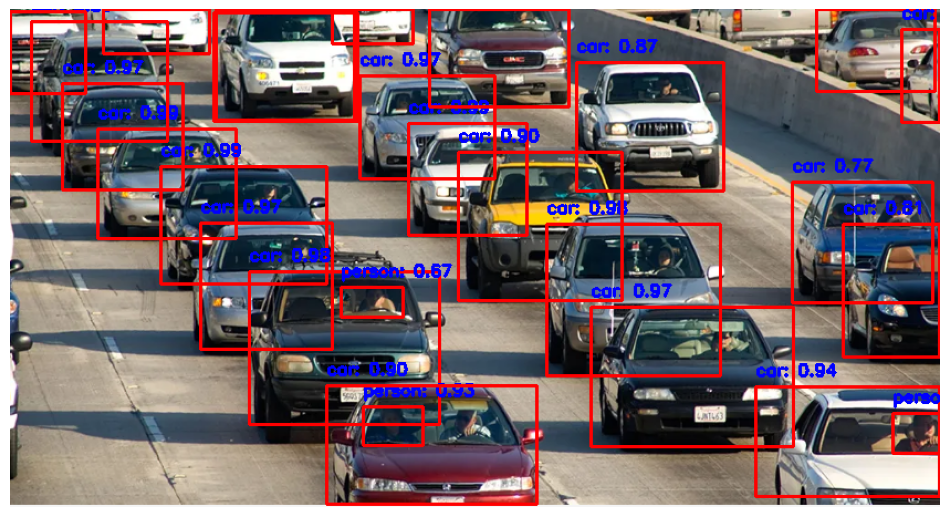

In [17]:
image_file = '/content/cars.png'

original_jit_state = tf.config.optimizer.get_jit()

original_run_functions_eagerly_state = tf.config.functions_run_eagerly()

try:
    tf.config.optimizer.set_jit(False)
    tf.config.run_functions_eagerly(True)
    predict_and_draw(image_file, yolo, class_names)
finally:
    tf.config.optimizer.set_jit(original_jit_state)
    tf.config.run_functions_eagerly(original_run_functions_eagerly_state)